In [18]:
from pathlib import Path
import nibabel as nib
import numpy as np
from numpy.typing import NDArray
from scipy.interpolate import BSpline, make_lsq_spline
from skimage import filters, segmentation
from scipy import ndimage
import matplotlib.pyplot as plt

nii = (
    "data/ABCD_QA_fMRI_16.nii.gz",
    "data/FBIRN_QA_fMRI_flip77_13.nii.gz",
    "data/FBIRN_QA_fMRI_flip77_14.nii.gz",
)

img = nib.load(nii[1])
data = img.get_fdata()  # numpy array, shape e.g. (X, Y, Z)
tr = img.header.get_zooms()[3]
dx = img.header.get_zooms()[0]

def trim_initial(data, tr, trim_sec):
    n = max(int(round(trim_sec / tr)), 0)
    return data[..., n:]

def segment_phantom(image):
    edges = filters.sobel(image, mode="wrap")
    labels = np.zeros_like(image, dtype=np.uint8)
    labels[image < np.quantile(image, 0.1)] = 1
    labels[image > np.quantile(image, 0.9)] = 2
    return segmentation.watershed(edges, labels) == 2

def extract_center_slice(data):
    mip = data.max(axis=-1)
    mask_size = [segment_phantom(i).sum() for i in np.moveaxis(mip, -1, 0)]
    center =  np.argmax(mask_size)
    return data[:,:,center,:]

def find_phantom_center(phantom_mask):    
    dist = ndimage.distance_transform_edt(phantom_mask)
    center = np.unravel_index(np.argmax(dist), dist.shape)
    return np.array(center)

def roi_indexes(center, n):
    p1 = center - (n-1)//2
    p2 = p1 + n
    return slice(p1[0], p2[0]), slice(p1[1], p2[1])

def largest_roi(phantom_mask, center):
    for n in range(1, 64, 2):
        roi = roi_indexes(center, n)
        if ~np.all(phantom_mask[roi]):
            return n-1

def roi_timeseries(data, center, n):
    roi = roi_indexes(center, n)
    return data[*roi,:].mean(axis=(0,1))

def spline_fit(
    y: NDArray[np.float64],
    tr: float,
    cutoff_s: float = 256.0,
    degree: int = 2,
) -> tuple[NDArray[np.float64], BSpline]:
    n = y.shape[0]
    x = np.arange(n, dtype=np.float64)

    # knots every `cutoff_s` seconds, over the fitted (steady-state) span only
    n_interior = max(int(round(n * tr / cutoff_s)) - 1, 0)
    t = np.concatenate((
        np.full(degree + 1, 0),
        np.linspace(0, n, n_interior + 2)[1:-1],
        np.full(degree + 1, n),
    ))
    spl = make_lsq_spline(x, y, t, k=degree)
    return spl(x)

def poly_degree(y, tr, cutoff_s=200.0):
    n = y.shape[-1]
    return int(np.round(n * tr / cutoff_s))

def poly_residuals(y, degree):
    nt = y.shape[-1]
    x = np.linspace(-1.0, 1.0, nt, dtype=float)

    # Design matrix: (nt, degree + 1)
    design = np.polynomial.legendre.legvander(x, degree)

    # Treat all leading-index combinations as separate signals.
    signals = y.reshape(-1, nt).T

    # coefficients: (degree + 1, number_of_signals)
    coefficients, *_ = np.linalg.lstsq(design, signals, rcond=None)

    fitted = (design @ coefficients).T
    return y - fitted.reshape(y.shape)

2


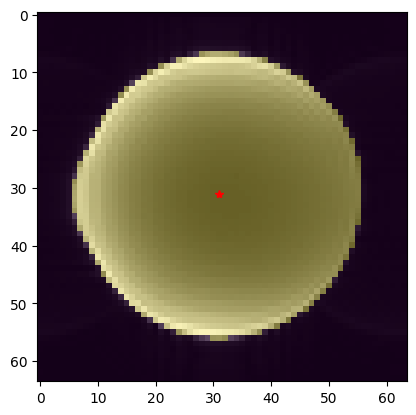

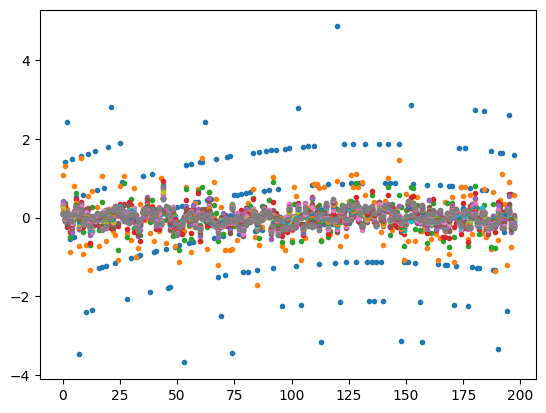

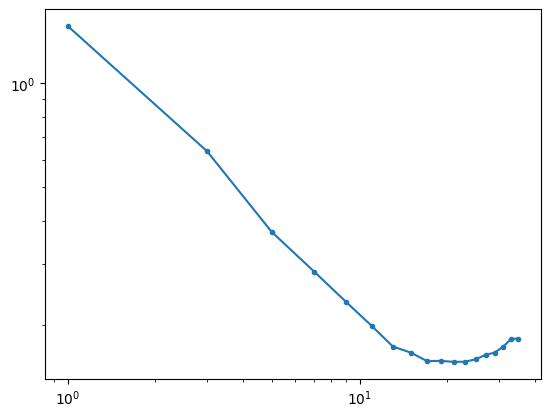

In [19]:
data = trim_initial(data, tr, 5.0)
center_slice = extract_center_slice(data)
phantom_mask = segment_phantom(center_slice.max(axis=-1))
center = find_phantom_center(phantom_mask)
k_max = largest_roi(phantom_mask, center)
degrees = poly_degree(center_slice, tr)

plt.imshow(center_slice.max(axis=-1), "gray")
plt.imshow(phantom_mask, alpha=0.3)
plt.plot(*center[::-1], 'r*')

plt.figure()

r = range(1, k_max, 2)
cv = []
print(deg)
for i in r:
    t = roi_timeseries(center_slice, center, i)
    res = poly_residuals(t, degrees)
    plt.plot(res, '.')
    cv.append(np.std(res, mean=0))

plt.figure()
plt.loglog(r, cv, '.-')

np.float64(9.710945200407801)

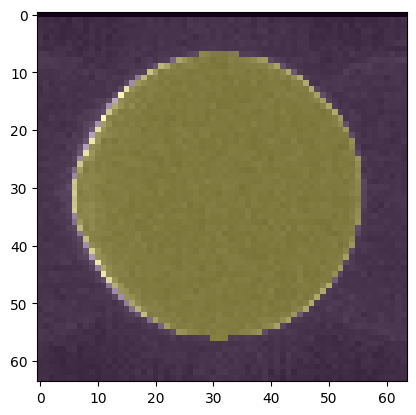

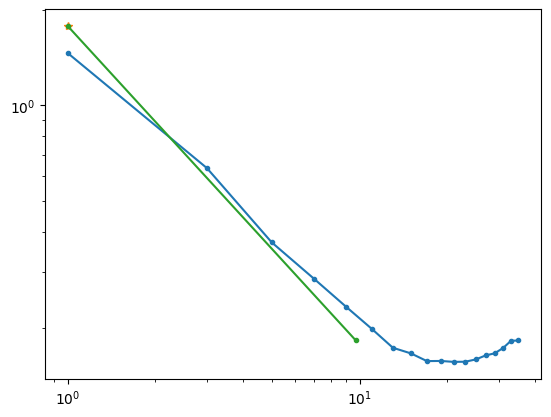

In [20]:
import numpy as np

res = polynomial_residuals(center_slice, 2)

mean_image = np.mean(center_slice, axis=-1)
fluct_noise = np.std(res, axis=-1, mean=0)
plt.imshow(fluct_noise, "gray")
plt.imshow(phantom_mask, alpha=0.3)

roi = roi_indexes(center, k_max)

s = fluct_noise[phantom_mask]
mu = mean_image[*roi]

cv1_pooled = float(np.sqrt(np.mean(s**2))) # RMS(s) / mean(mu)

cv1_pooled
rdc = cv1_pooled / cv[-1]

plt.figure()
plt.loglog(r, cv, '.-')
plt.loglog(1, cv1_pooled, '*')
plt.loglog((1,rdc), (cv1_pooled, cv[-1]), '.-')

rdc

In [57]:
"""Least-squares surface fit on a regular triangular lattice, with a mask.

The surface is modelled as a linear combination of piecewise-linear "hat"
basis functions anchored at the nodes of a regular triangular (hexagonal)
lattice. Only unmasked pixels contribute to the fit; a graph-Laplacian
penalty keeps nodes with little/no data well conditioned and controls
smoothness.
"""

from __future__ import annotations

import numpy as np
from numpy.typing import NDArray
from scipy.sparse import coo_matrix, csr_matrix, diags
from scipy.sparse.linalg import spsolve
from scipy.spatial import Delaunay

FloatArray = NDArray[np.float64]


def triangular_grid(
    shape: tuple[int, int], spacing: float, pad: float | None = None
) -> FloatArray:
    """Regular triangular lattice of (x, y) nodes covering an ``(ny, nx)`` image.

    Rows are ``spacing * sqrt(3)/2`` apart, every other row offset by
    ``spacing / 2``, so all triangles are (near-)equilateral with edge
    length ``spacing``. The lattice is padded past the image edges so
    every pixel falls inside a triangle.
    """
    if pad is None:
        pad = spacing
    ny, nx = shape
    row_step = spacing * np.sqrt(3.0) / 2.0
    ys = np.arange(-pad, (ny - 1) + pad + row_step, row_step)
    rows = []
    for i, y in enumerate(ys):
        offset = 0.5 * spacing if i % 2 else 0.0
        xs = np.arange(-pad + offset, (nx - 1) + pad + spacing, spacing)
        rows.append(np.column_stack([xs, np.full_like(xs, y)]))
    return np.vstack(rows)


def _design_matrix(tri: Delaunay, xy: FloatArray) -> csr_matrix:
    """Sparse (n_points, n_nodes) matrix of barycentric weights.

    Row i holds the three barycentric coordinates of point i w.r.t. the
    vertices of its containing triangle, i.e. A @ node_values evaluates
    the piecewise-linear interpolant at the points.
    """
    simplex = tri.find_simplex(xy)
    if np.any(simplex < 0):
        raise ValueError("Some points fall outside the lattice; increase `pad`.")
    T = tri.transform[simplex]  # (m, 3, 2)
    b2 = np.einsum("mij,mj->mi", T[:, :2, :], xy - T[:, 2, :])
    bary = np.concatenate([b2, 1.0 - b2.sum(axis=1, keepdims=True)], axis=1)
    verts = tri.simplices[simplex]  # (m, 3)
    rows = np.repeat(np.arange(xy.shape[0]), 3)
    return coo_matrix(
        (bary.ravel(), (rows, verts.ravel())),
        shape=(xy.shape[0], tri.npoints),
    ).tocsr()


def _graph_laplacian(tri: Delaunay) -> csr_matrix:
    """Umbrella (graph) Laplacian over the triangulation edges."""
    s = tri.simplices
    e = np.vstack([s[:, [0, 1]], s[:, [1, 2]], s[:, [2, 0]]])
    e = np.unique(np.sort(e, axis=1), axis=0)
    n = tri.npoints
    w = coo_matrix((np.ones(len(e)), (e[:, 0], e[:, 1])), shape=(n, n))
    w = (w + w.T).tocsr()
    return (diags(np.asarray(w.sum(axis=1)).ravel()) - w).tocsr()


def fit_masked_surface(
    z: FloatArray,
    mask: NDArray[np.bool_],
    spacing: float,
    smooth: float = 1e-2,
) -> tuple[FloatArray, FloatArray, Delaunay]:
    """Fit a triangular-lattice surface to ``z`` where ``mask`` is True.

    Solves ``min_c ||A c - z[mask]||^2 + smooth * n_data * ||L c||^2``
    via the (sparse) normal equations.

    Returns ``(fitted, coef, tri)`` where ``fitted`` is the surface
    evaluated on the full pixel grid, ``coef`` the node values, and
    ``tri`` the Delaunay triangulation of the lattice.
    """
    z = np.asarray(z, dtype=np.float64)
    mask = np.asarray(mask, dtype=bool)

    nodes = triangular_grid(z.shape, spacing)
    tri = Delaunay(nodes)

    yy, xx = np.nonzero(mask)
    xy_data = np.column_stack([xx, yy]).astype(np.float64)
    A = _design_matrix(tri, xy_data)
    L = _graph_laplacian(tri)

    lam = smooth * mask.sum() / tri.npoints
    lhs = (A.T @ A + lam * (L.T @ L)).tocsc()
    rhs = A.T @ z[mask]
    coef = spsolve(lhs, rhs)

    yy_all, xx_all = np.mgrid[0 : z.shape[0], 0 : z.shape[1]]
    xy_all = np.column_stack([xx_all.ravel(), yy_all.ravel()]).astype(np.float64)
    fitted = (_design_matrix(tri, xy_all) @ coef).reshape(z.shape)
    return fitted, coef, tri


if __name__ == "__main__":
    rng = np.random.default_rng(0)
    ny, nx = 200, 300
    yy, xx = np.mgrid[0:ny, 0:nx]
    truth = np.sin(xx / 40.0) * np.cos(yy / 55.0) + 0.002 * xx
    z = truth + rng.normal(0.0, 0.05, size=truth.shape)

    # mask out a disc and random 30% of pixels
    mask = rng.random(z.shape) > 0.3
    mask &= (xx - 150) ** 2 + (yy - 100) ** 2 > 50**2

    fitted, coef, tri = fit_masked_surface(z, mask, spacing=15.0, smooth=1e-2)

    rms_valid = np.sqrt(np.mean((fitted[mask] - truth[mask]) ** 2))
    rms_hole = np.sqrt(np.mean((fitted[~mask] - truth[~mask]) ** 2))
    print(f"nodes: {tri.npoints}, valid pixels: {mask.sum()}")
    print(f"RMS error vs truth (valid pixels): {rms_valid:.4f}")
    print(f"RMS error vs truth (masked pixels): {rms_hole:.4f}")

nodes: 437, valid pixels: 36447
RMS error vs truth (valid pixels): 0.0051
RMS error vs truth (masked pixels): 0.0090


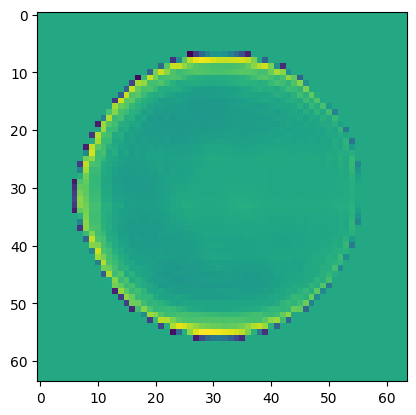

In [75]:
img = center_slice.mean(axis=-1)
mask = img > 500
plt.imshow(img,"gray")

fitted, coef, tri = fit_masked_surface(img, mask, spacing=10, smooth=1e-1)
plt.imshow((img - fitted) * mask)

In [76]:
"""C1 surface fit to masked data using scikit-fem (Argyris element).

Penalized least squares: min_c ||P c - z||^2 + lam * c^T K c,
where P is the point-evaluation ("probes") matrix at unmasked pixels
and K is the assembled thin-plate bending energy (integral of the
squared Hessian). This is the FEM analogue of a thin-plate smoothing
spline, with the triangular lattice as the mesh.
"""

from __future__ import annotations

import numpy as np
from scipy.sparse.linalg import spsolve
from scipy.spatial import Delaunay
from skfem import Basis, BilinearForm, ElementTriArgyris, MeshTri
from skfem.helpers import dd, ddot

from tri_spline_fit import triangular_grid


def fit_masked_surface_c1(
    z: np.ndarray,
    mask: np.ndarray,
    spacing: float,
    smooth: float = 1e-4,
) -> np.ndarray:
    z = np.asarray(z, dtype=np.float64)
    nodes = triangular_grid(z.shape, spacing)
    tri = Delaunay(nodes)
    mesh = MeshTri(nodes.T.copy(), tri.simplices.T.copy())
    basis = Basis(mesh, ElementTriArgyris())

    @BilinearForm
    def bending(u, v, _):
        return ddot(dd(u), dd(v))

    K = bending.assemble(basis)

    yy, xx = np.nonzero(mask)
    P = basis.probes(np.vstack([xx, yy]).astype(np.float64))
    lam = smooth * mask.sum() / basis.N * spacing**4  # dimensionally consistent
    lhs = (P.T @ P + lam * K).tocsc()
    coef = spsolve(lhs, P.T @ z[mask])

    yy_all, xx_all = np.mgrid[0 : z.shape[0], 0 : z.shape[1]]
    P_all = basis.probes(
        np.vstack([xx_all.ravel(), yy_all.ravel()]).astype(np.float64)
    )
    return (P_all @ coef).reshape(z.shape)

ImportError: cannot import name 'Basis' from 'skfem' (/home/jstorrs/src/fmri-qa/.venv/lib/python3.13/site-packages/skfem/__init__.py)

In [1]:
from skfem import Basis

ImportError: cannot import name 'Basis' from 'skfem' (unknown location)

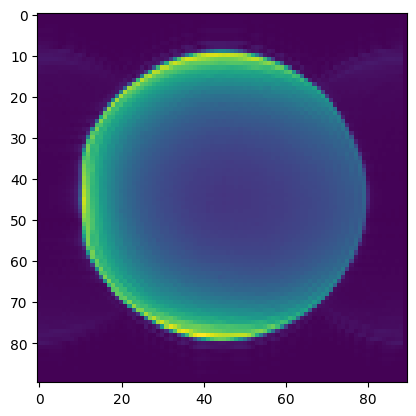

In [54]:
image_gray = center_slice.mean(axis=-1)
plt.imshow(image_gray)

In [88]:
import numpy as np
from skimage import color, feature, transform, draw

# 1. Edge detection (imfindcircles does this internally)
edges = feature.canny(image_gray, sigma=3)

rmax = int(image_gray.shape[0]/2)
# 2. Hough transform over candidate radii
radii = np.arange(rmax//2, rmax)  # like imfindcircles' [rmin rmax]
hough_res = transform.hough_circle(edges, radii)

# 3. Extract the best circles
accums, cx, cy, found_radii = transform.hough_circle_peaks(
    hough_res, radii, total_num_peaks=1
)

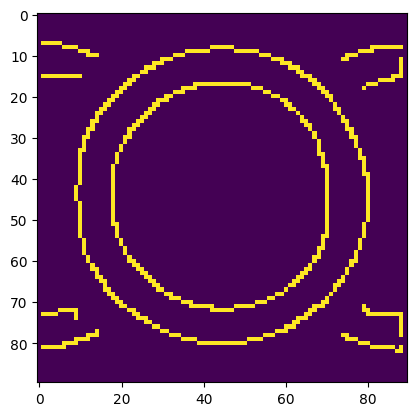

In [83]:
plt.imshow(edges)

In [84]:
radii

array([22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38,
       39, 40, 41, 42, 43, 44])

In [85]:
found_radii

array([36])

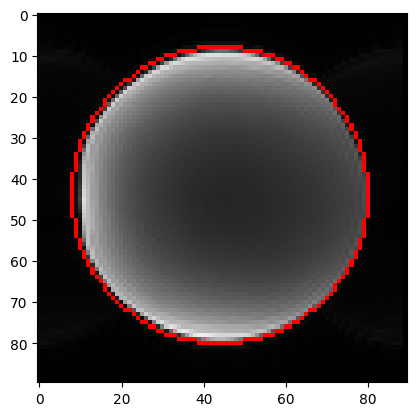

In [92]:
image = color.gray2rgb(image_gray/4000)
circy, circx = draw.circle_perimeter(cx[0], cy[0], found_radii[0], shape=image.shape)
image[circy, circx] = (1, 0, 0)

plt.imshow(image)

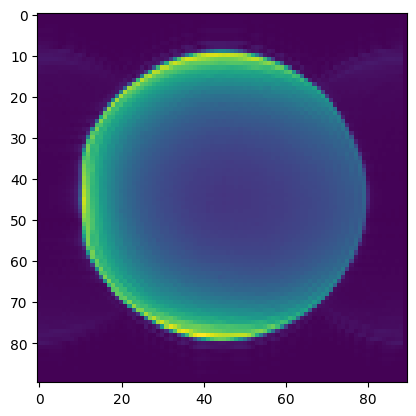

In [94]:
image = image_gray
plt.imshow(image_gray)

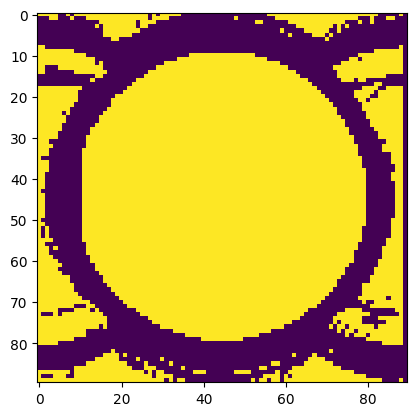

In [115]:
from skimage import filters, morphology

thr = 0.5*morphology.dilation(image, morphology.disk(5))
plt.imshow(image > thr)

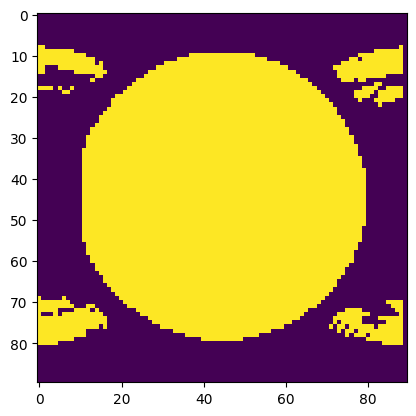

In [125]:
thr = 0.5*morphology.dilation(image, morphology.disk(5))
mask1 = image > thr
mask2 = image > 2*np.quantile(image, (4-np.pi)/4)

plt.imshow(mask1 & mask2)

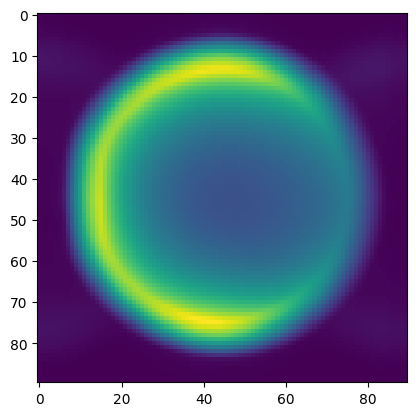

In [131]:
from scipy import ndimage

plt.imshow(ndimage.convolve(image, morphology.disk(5)))

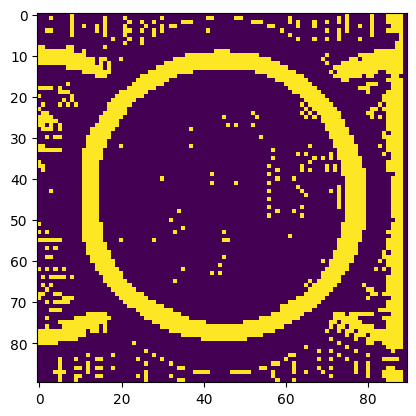

In [139]:
disk = morphology.disk(5, dtype=np.float64)
disk /= disk.sum()
plt.imshow(image > ndimage.convolve(image, disk))

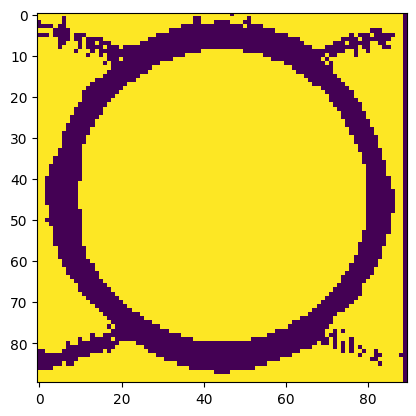

In [248]:
i1 = morphology.opening(image, morphology.disk(5))
i2 = morphology.dilation(i1, morphology.disk(5))

plt.imshow(image > 0.5*i2)

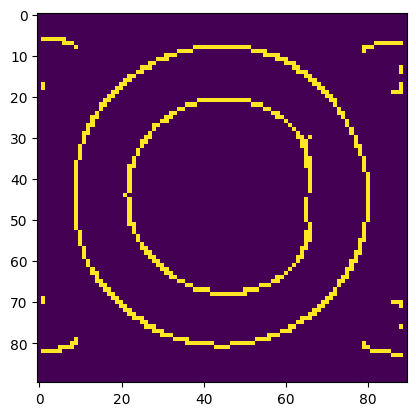

In [247]:
from skimage import feature

plt.imshow(feature.canny(image, 5))

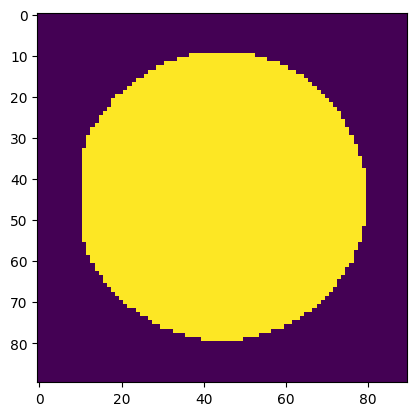

In [176]:
thr = np.maximum(i1/2, 4*np.quantile(i1, (4-np.pi)/4))
plt.imshow(np.maximum(image > thr, 0))

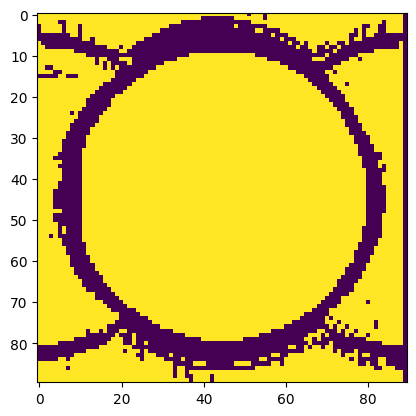

In [185]:
mask = image > 0.5*morphology.dilation(image, morphology.disk(3))

plt.imshow(mask)

In [186]:
s = np.linspace(0, 2*np.pi, 100)
init = 50 * np.array([np.sin(s), np.cos(s)]).T + 50

In [187]:
init.shape

(100, 2)

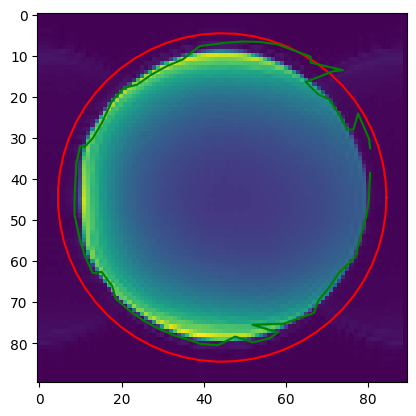

In [223]:
from skimage import segmentation


plt.imshow(image)
n = np.array(image.shape)
s = np.linspace(0, 2*np.pi, 60)

init = (0.5*n.min() - 5) * np.array([np.sin(s), np.cos(s)]).T + (n-1)/2
snake = segmentation.active_contour(
    image,
    init,
    alpha=0.015,
    beta=10,
    gamma=0.001,
)
snake = np.clip(snake, 0, 90)

plt.plot(init[:,1], init[:,0], 'r')
plt.plot(snake[:,1], snake[:,0], 'g')

In [217]:
snake

array([[  42.5       ,   78.5       ],
       [  49.03695679,   78.41946706],
       [  43.56369814,   78.17819251],
       [  48.07004977,   77.77714789],
       [  50.54591949,   81.21769771],
       [  52.98133783,   80.27979131],
       [  57.36649823,   75.63631685],
       [  53.69240213,   74.61706153],
       [  57.94786944,   81.45397508],
       [  60.1256327 ,   74.15014131],
       [  70.21629594,   66.7108103 ],
       [  70.21150439,   63.0972859 ],
       [  68.10316133,   63.44936152],
       [  73.88366835,   59.64037646],
       [  73.54585857,   59.72210668],
       [  69.08303808,   57.70227638],
       [  70.4890172 ,   57.5890187 ],
       [  73.75813454,   53.39084299],
       [  76.88527981,   51.11660052],
       [  75.86591441,   44.77544886],
       [  76.69608966,   36.37681501],
       [  75.37246273,   39.93035742],
       [  77.89231012,   41.44592711],
       [  80.25353858,   44.93352857],
       [  80.45469357,   46.40327663],
       [  80.49496511,   

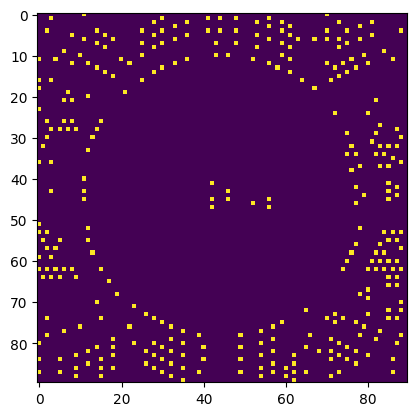

In [255]:
i1 = morphology.dilation(image, np.ones((3,3), dtype=bool), mode="wrap")

plt.imshow(image == i1)

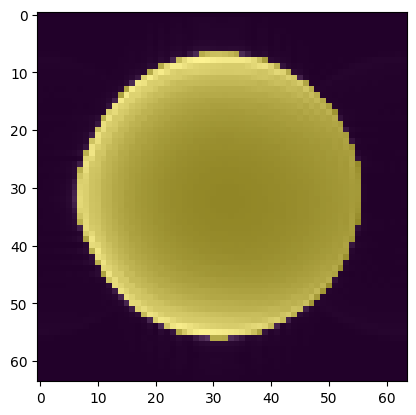

In [295]:
image = center_slice.mean(axis=-1)
edges = filters.sobel(image, mode="wrap")
seeds = np.zeros_like(image, dtype=np.uint8)
seeds[image < np.quantile(image, 0.1)] = 1
seeds[image > np.quantile(image, 0.9)] = 2
mask = segmentation.watershed(edges, seeds) == 2


array([31, 31])

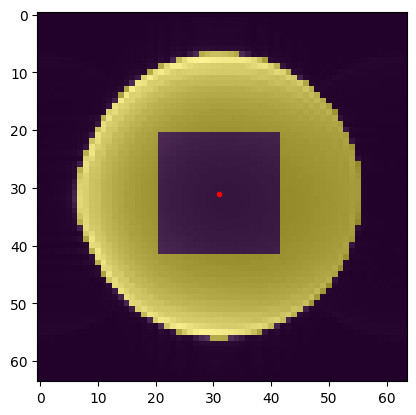

In [325]:
z = np.zeros_like(mask)
z[i,j] = 1
z.sum(), 21*21

(np.int64(441), 441)

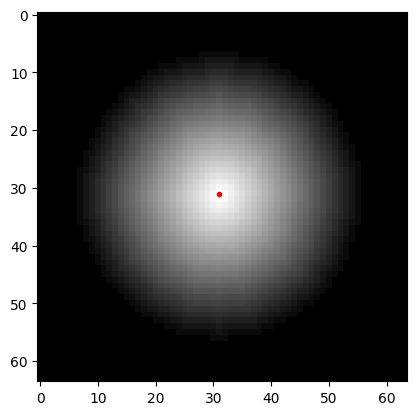

In [299]:
dist = ndimage.distance_transform_edt(mask)
row, col = np.unravel_index(np.argmax(dist), dist.shape)

plt.imshow(dist, 'gray')
plt.plot(row, col, 'r.')

In [313]:
center

NameError: name 'center' is not defined